# E-mail campaign measurement

One project, one question in three parts, on a randomized e-mail test of 64,000 customers (Hillstrom):

1. **Did the campaign work?** Test health checks, effects, CUPED, GLM, Bayesian readout, subgroups
2. **Could we have measured it without a test?** Matching, weighting, doubly robust and double ML, checked against the experiment's answer
3. **How should the next test be designed?** Sample size, whether visits can stand in for spend, CUPED, and randomizing whole markets

**In Google Colab:** Runtime → Run all. About 2 minutes; no accounts or keys needed.

In [1]:
import os
if not os.path.exists("run_all.py"):          # in Colab: fetch the project
    !git clone -q https://github.com/Dorcas-Okaidjah/causal-measurement-lab.git
    %cd causal-measurement-lab
!pip install -q -r requirements.txt

## Check the methods on simulated data with known answers (~1 minute)

In [2]:
!python -m pytest -q 2>&1 | tail -2

....................                                                     [100%]
20 passed in 44.49s


## Get the data

In [3]:
!python -m src.data --download
!python -m src.data --inspect

  could not reach www.minethatdata.com (<urlopen error [Errno -2] Name or service not known>); trying next source


  Hillstrom: saved from raw.githubusercontent.com (checksum verified)



64,000 customers
                visit  conversion   spend
arm                                      
Mens E-Mail    0.1828      0.0125  1.4226
No E-Mail      0.1062      0.0057  0.6528
Womens E-Mail  0.1514      0.0088  1.0772

pre-period covariates:


           count    mean     std    min    25%     50%     75%      max
recency  64000.0    5.76    3.51   1.00   2.00    6.00    9.00    12.00
history  64000.0  242.09  256.16  29.99  64.66  158.11  325.66  3345.93
mens     64000.0    0.55    0.50   0.00   0.00    1.00    1.00     1.00
womens   64000.0    0.55    0.50   0.00   0.00    1.00    1.00     1.00
newbie   64000.0    0.50    0.50   0.00   0.00    1.00    1.00     1.00


## Run all three parts

In [4]:
!python run_all.py

1/5 loading data


2/5 part 1: did the campaign work?


3/5 part 2: could we have measured it without a test?


4/5 part 3: how should the next test be designed?


5/5 writing charts, tables and the summary


done in 24.9s -> /home/claude/causal-measurement-lab/reports/summary.md


## The readout

In [5]:
from IPython.display import Markdown, Image, display
display(Markdown(open("reports/summary.md").read()))

# E-mail campaign measurement readout

## Part 1. Did the campaign work? (randomized test, 64,000 customers)

**Test health.** Group sizes Womens E-Mail: 21,387, Mens E-Mail: 21,307, No E-Mail: 21,306; sample-ratio check p = 0.90 (pass). Largest pre-period imbalance |SMD| = 0.012 (threshold 0.1).

| E-mail | Metric | Control | Treated | Effect (95% CI) | Lift (95% CI) | Holm p |
|---|---|---|---|---|---|---|
| Mens E-Mail | visit | 10.62% | 18.28% | 7.66% (7.00% to 8.32%) | +72% (+64% to +81%) | < 0.001 |
| Mens E-Mail | conversion | 0.57% | 1.25% | 0.68% (0.50% to 0.86%) | +119% (+77% to +171%) | < 0.001 |
| Mens E-Mail | spend | 0.65 | 1.42 | 0.77 (0.49 to 1.05) | +118% (+63% to +192%) | < 0.001 |
| Womens E-Mail | visit | 10.62% | 15.14% | 4.52% (3.89% to 5.16%) | +43% (+36% to +50%) | < 0.001 |
| Womens E-Mail | conversion | 0.57% | 0.88% | 0.31% (0.15% to 0.47%) | +54% (+23% to +94%) | < 0.001 |
| Womens E-Mail | spend | 0.65 | 1.08 | 0.42 (0.17 to 0.68) | +65% (+22% to +124%) | 0.001 |

Logistic GLM (visit, with pre-period covariates): odds ratio Mens E-Mail 1.91 (1.81-2.02), +7.6% points; Womens E-Mail 1.52 (1.44-1.61), +4.5% points.

**CUPED.** Using prior-year spend removed only 0.04% of the variance in spend, because it correlates just 0.02 with two-week spend.

**Bayesian view.** Probability each e-mail increases spend: Mens E-Mail > 99.99% (expected loss if wrong $0.0000 per customer); Womens E-Mail 99.85% (expected loss if wrong $0.0001 per customer).

**Subgroups.** No measurable spend effect (Holm p > 0.05) in: Womens E-Mail / bought_mens=1; Womens E-Mail / bought_womens=0; Womens E-Mail / new_customer=0.

## Part 2. Could we have measured it without a test?

Treated customers were thinned by a targeting rule favouring engaged customers (11,225 of 21,387 kept). Randomized truth for the Women's e-mail effect on visit rate: 4.52% (3.89% to 5.16%).

| Method | Estimate | 95% CI | Gap to truth |
|---|---|---|---|
| Naive difference | 6.31% | 5.50% to 7.12% | +1.79 pts |
| Regression adjustment | 4.50% | 3.67% to 5.33% | -0.02 pts |
| Propensity matching | 4.32% | 3.69% to 4.95% | -0.20 pts |
| Inverse probability weighting | 4.59% | 3.73% to 5.44% | +0.07 pts |
| Doubly robust (AIPW) | 4.39% | 3.54% to 5.23% | -0.14 pts |
| Double ML | 4.57% | 3.74% to 5.40% | +0.05 pts |
| Doubly robust (AIPW), past spend unobserved | 4.74% | 3.92% to 5.55% | +0.21 pts |
| Inverse probability weighting, past spend unobserved | 4.89% | 4.08% to 5.71% | +0.37 pts |

Balance: largest |SMD| 0.48 before weighting, 0.06 after. Overlap: 100% of treated and 100% of untreated customers inside the common range.

## Part 3. How should the next test be designed?

**Sample size.** With 21,306 customers per group the smallest detectable spend effect is $0.31 (48% of the control mean). Detecting a 10% spend lift needs 494,680 per group; a 10% visit lift needs 13,217.

**Can visit stand in for spend?** Visitors spend more (customer-level correlation 0.17), but across 18 segments the visit effect predicts the spend effect only weakly (split-sample correlation 0.27; 90% of splits between -0.08 and 0.50). At campaign level both e-mails earn about $10 and $9 per extra visit.

**CUPED.** All pre-period data together predicts 3.0% of the variance in visits and 0.15% in spend, so CUPED would save little here. A metric measured just before the test would do better.

**Randomizing whole markets.** 57 markets (location type x channel x spending tier), about 374 customers each in the control group. Visit-rate ICC 0.013, design effect 5.9. To detect a 15% visit lift, customer randomization needs 5,875 customers per arm; market randomization needs 94 markets per arm, more than exist. In one example market test, the naive standard error was 0.0042 and the cluster-robust one 0.0128.

Simulated power: customers randomized 97%, markets randomized 20%. Randomizing markets but analysing customers as independent declared an effect 54% of the time when there was none (should be 5%).



### Part 1: did the campaign work?

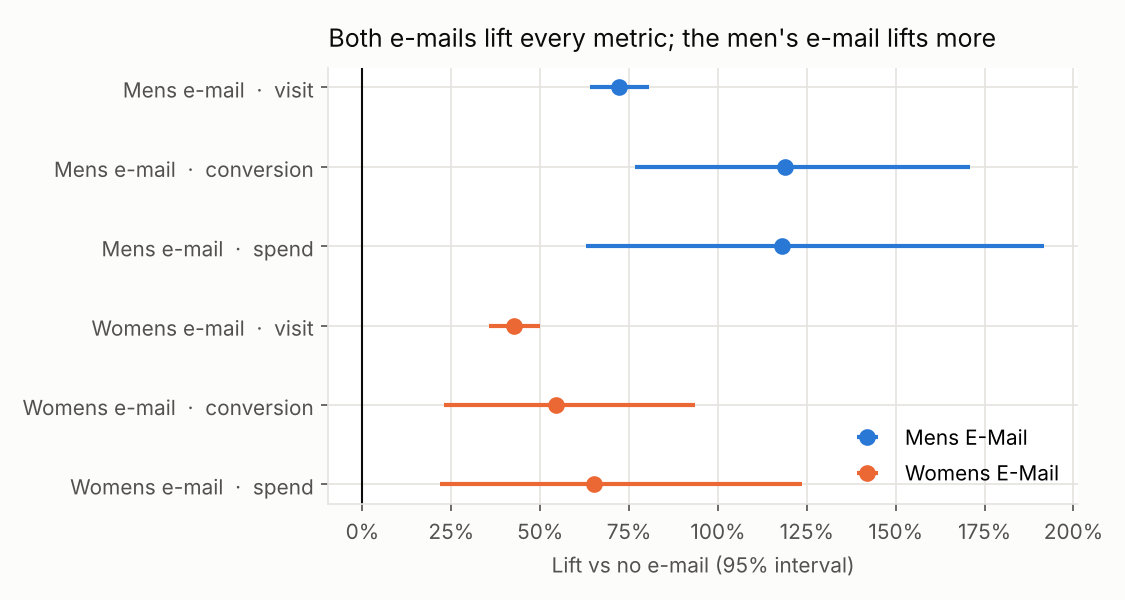

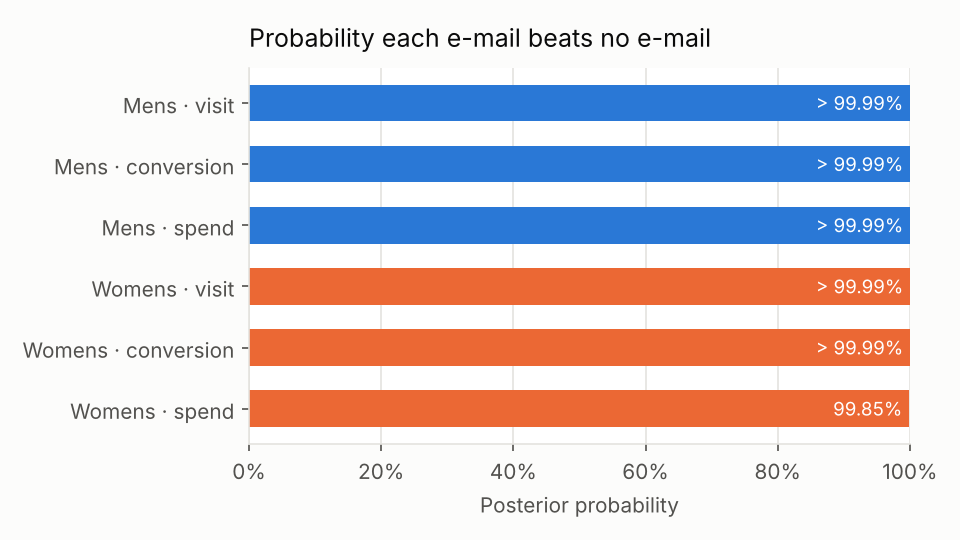

In [6]:
for f in ["experiment_lift", "bayes_probability"]:
    display(Image(f"reports/{f}.png", width=700))

### Part 2: could we have measured it without a test?

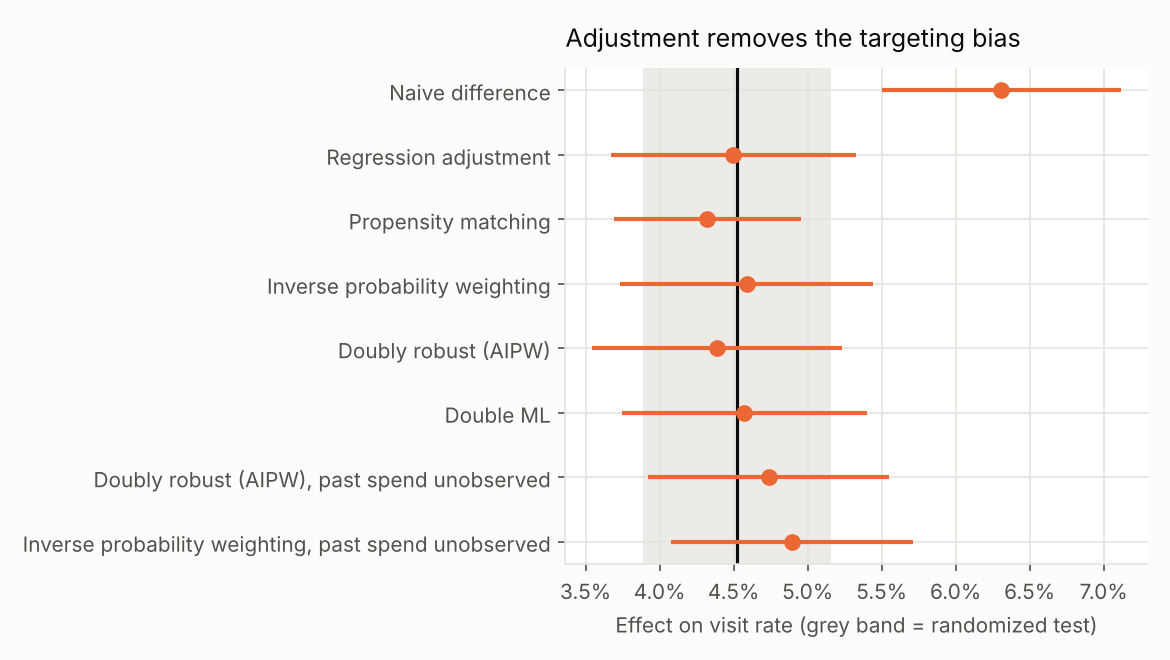

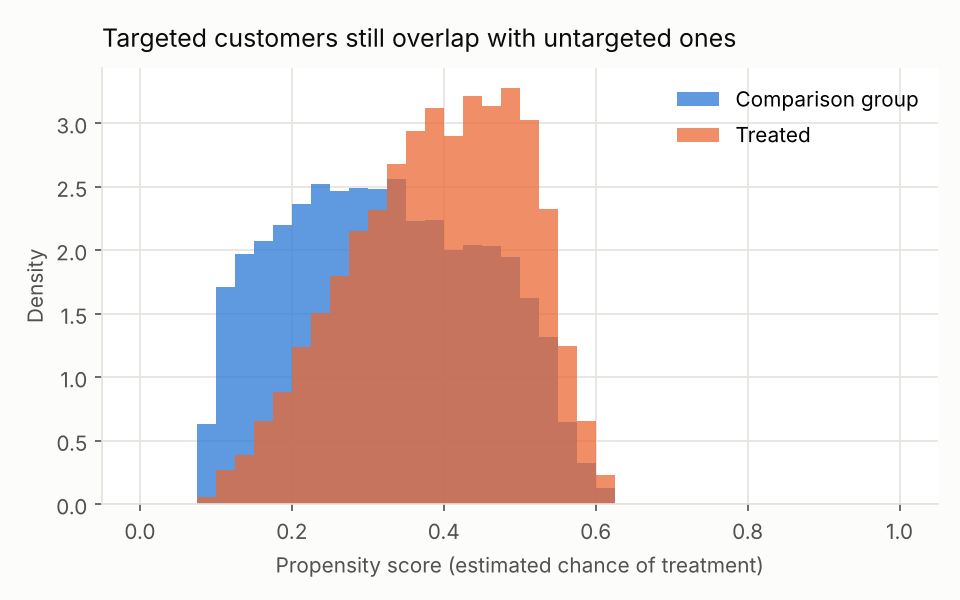

In [7]:
for f in ["without_a_test", "targeting_overlap"]:
    display(Image(f"reports/{f}.png", width=700))

### Part 3: how should the next test be designed?

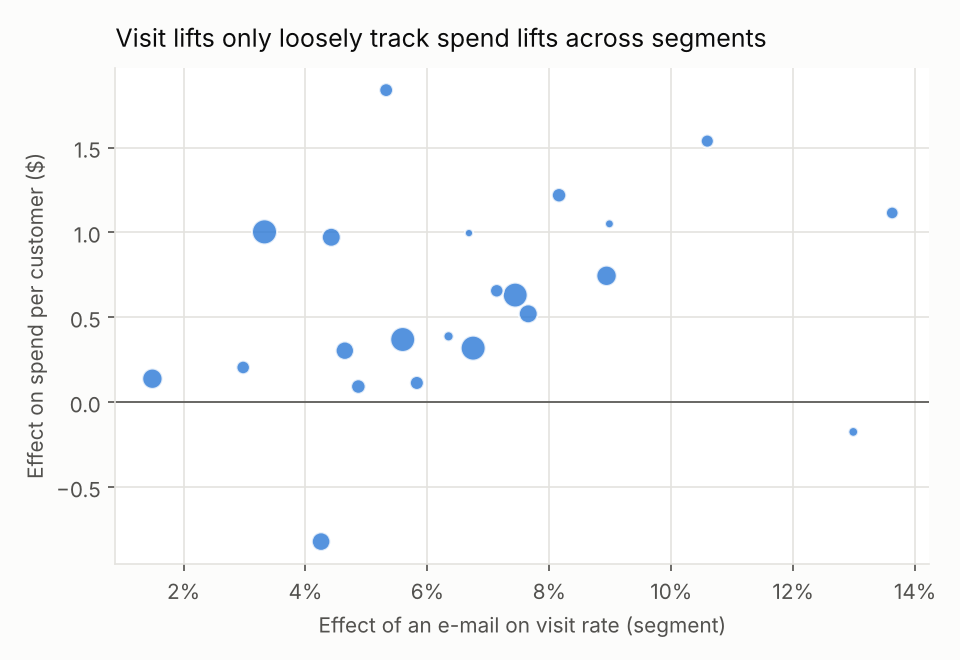

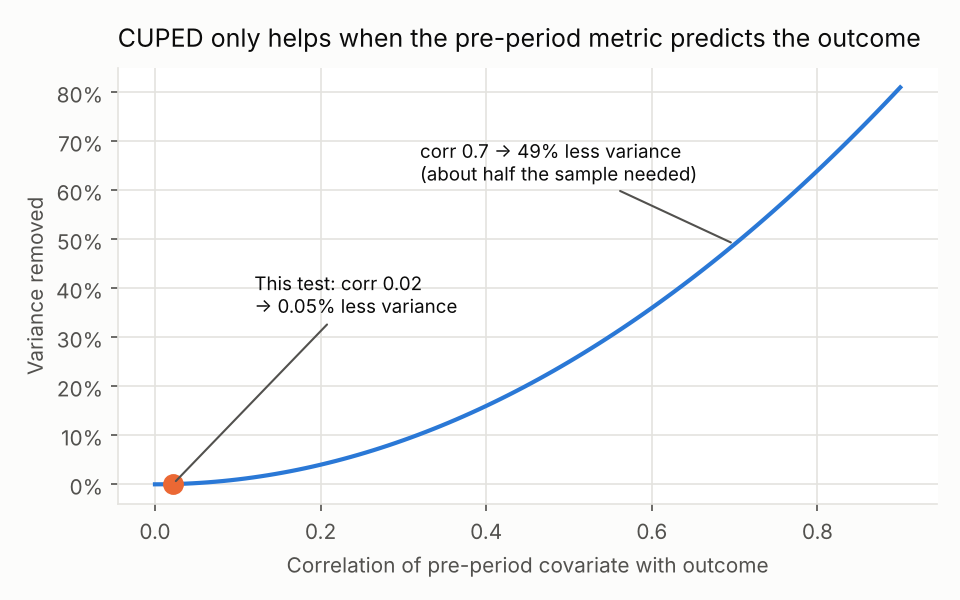

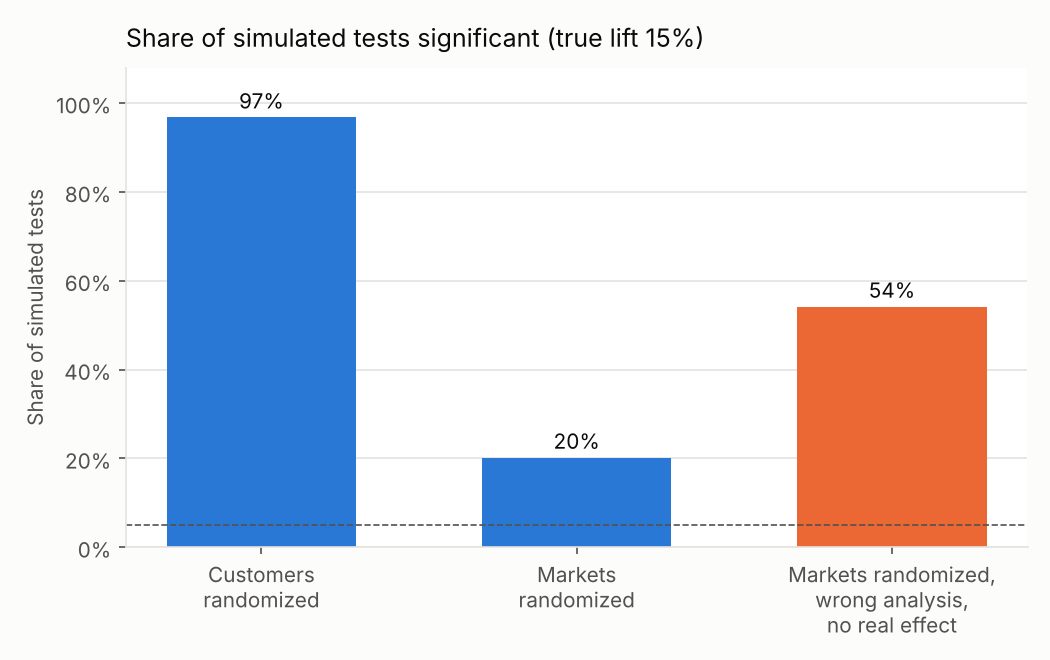

In [8]:
for f in ["proxy_validation", "cuped_variance_reduction", "market_randomization"]:
    display(Image(f"reports/{f}.png", width=700))